#--------------------------------
# SPO2 & HR
#-------------------------------

Rows removed: 3

FINAL SAMPLE
(389, 7)
50 unique participants

MIXED MODEL
                 Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      HR        
No. Observations:      389          Method:                  REML      
No. Groups:            50           Scale:                   78.1988   
Min. group size:       1            Log-Likelihood:          -1446.2780
Max. group size:       8            Converged:               Yes       
Mean group size:       7.8                                             
-----------------------------------------------------------------------
                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                    75.412    1.933 39.005 0.000 71.623 79.201
Session[T.1]                  0.235    1.793  0.131 0.896 -3.280  3.749
Timepoint[T.2]               -0.704    1.793 -0.393 0.695 -4.219  2.810
Timepo

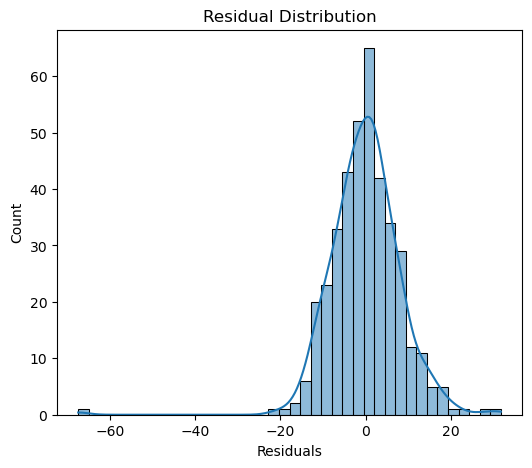

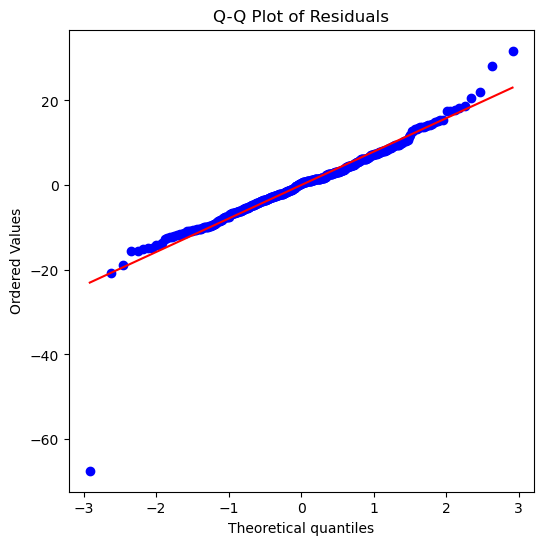


SHAPIRO-WILK TEST
W = 0.9197
p = 0.0000


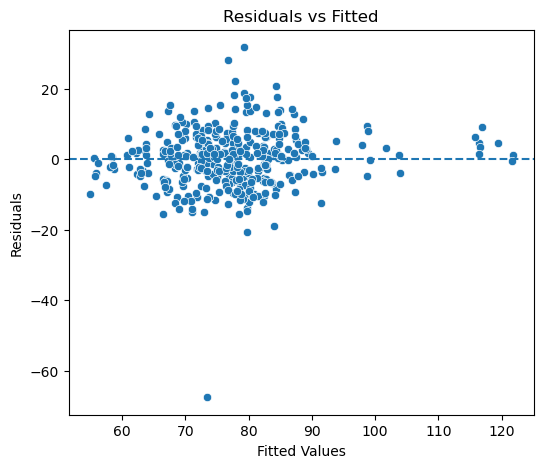

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from pathlib import Path


FORMULA = "SpO2 ~ Session * Timepoint"

# REML model used for primary inference
# GEE model used as a robust sensitivity analysis

# =====================================================
# FILE PATH
# =====================================================

file_path = Path("data") / "SpO2_continuous.csv"

# For intermittent analyses use:
# file_path = Path("data") / "SpO2_intermittent.csv"

df = pd.read_csv(
    file_path
)

# =====================================================
# REMOVE MISSING VALUES
# =====================================================

model_df = df.dropna().copy()

# =====================================================
# REMOVE OUTLIERS (3 SD)
# =====================================================

z_scores = stats.zscore(
    model_df['SpO2']
)

model_df['zscore'] = z_scores

# keep only rows within ±3 SD
model_df = model_df[
    np.abs(model_df['zscore']) < 3
]

# remove helper column
model_df = model_df.drop(
    columns='zscore'
)

print("Rows removed:", len(z_scores) - len(model_df))
# =====================================================
# RESET INDEX
# =====================================================

model_df = model_df.reset_index(
    drop=True
)

# =====================================================
# CATEGORICAL VARIABLES
# =====================================================

model_df['Session'] = (
    model_df['Session']
    .astype('category')
)

model_df['Timepoint'] = (
    model_df['Timepoint']
    .astype('category')
)

# =====================================================
# CHECK SAMPLE SIZE
# =====================================================

print("\n==============================")
print("FINAL SAMPLE")
print("==============================")

print(model_df.shape)

print(
    model_df['sub_id'].nunique(),
    "unique participants"
)

# =====================================================
# FIT MIXED MODEL
# =====================================================


mixed_model = smf.mixedlm(

    FORMULA,

    data=model_df,

    groups=model_df["sub_id"]
)

mixed_result = mixed_model.fit(
    reml=True
)

print("\n==============================")
print("MIXED MODEL")
print("==============================")

print(mixed_result.summary())

# =====================================================
# ROBUST GEE MODEL
# =====================================================

gee_model = smf.gee(

    FORMULA,

    groups="sub_id",

    data=model_df,

    family=sm.families.Gaussian(),

    cov_struct=sm.cov_struct.Exchangeable()
)

gee_result = gee_model.fit()

print("\n==============================")
print("GEE MODEL")
print("==============================")

print(gee_result.summary())

# =====================================================
# RESIDUALS
# =====================================================

residuals = mixed_result.resid

# =====================================================
# HISTOGRAM
# =====================================================

plt.figure(figsize=(6,5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Residual Distribution")

plt.xlabel("Residuals")

plt.show()

# =====================================================
# Q-Q PLOT
# =====================================================

plt.figure(figsize=(6,6))

stats.probplot(

    residuals,

    dist="norm",

    plot=plt
)

plt.title("Q-Q Plot of Residuals")

plt.show()

# =====================================================
# SHAPIRO-WILK TEST
# =====================================================

shapiro_test = stats.shapiro(
    residuals
)

print("\n==============================")
print("SHAPIRO-WILK TEST")
print("==============================")

print(
    f"W = {shapiro_test.statistic:.4f}"
)

print(
    f"p = {shapiro_test.pvalue:.4f}"
)

# =====================================================
# RESIDUALS VS FITTED
# =====================================================

fitted = mixed_result.fittedvalues

plt.figure(figsize=(6,5))

sns.scatterplot(
    x=fitted,
    y=residuals
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Fitted Values")

plt.ylabel("Residuals")

plt.title("Residuals vs Fitted")

plt.show()

#-------------------------------------------
#   Hypothesis #1 & #2: SPACE & EEG Differences in Hypoxia
#-------------------------------------------

In [ ]:
import pandas as pd
import statsmodels.formula.api as smf
from pathlib import Path

FORMULA = "offset_mean_change ~ session * intervention" #change for SPACE and EEG variables

# =====================================================
# LOAD DATA
# =====================================================

file_path = Path("data") / "MASTER_CHANGE_WITH_SPO2.csv"

df = pd.read_csv(
    file_path
)

# =====================================================
# CREATE EC DATAFRAME
# =====================================================

df_ec = (
    df[
        df['eye_state'] == 'EC'
    ]
    .copy()
)

# =====================================================
# CREATE EO DATAFRAME
# =====================================================

df_eo = (
    df[
        df['eye_state'] == 'EO'
    ]
    .copy()
)

# =====================================================
# OPTIONAL:
# REMOVE eye_state COLUMN
# =====================================================

df_ec = df_ec.drop(
    columns='eye_state'
)

df_eo = df_eo.drop(
    columns='eye_state'
)

# =====================================================
# SUMMARY
# =====================================================

print("\n==============================")
print("EC DATAFRAME")
print("==============================")

print("\nShape:")
print(df_ec.shape)

print("\nPreview:")
print(df_ec.head())

print("\n==============================")
print("EO DATAFRAME")
print("==============================")

print("\nShape:")
print(df_eo.shape)

print("\nPreview:")
print(df_eo.head())

# =====================================================
# SAVE
# =====================================================

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

ec_save = results_dir / "MASTER_CHANGE_WITH_SPO2_EC.csv"
eo_save = results_dir / "MASTER_CHANGE_WITH_SPO2_EO.csv"

df_ec.to_csv(
    ec_save,
    index=False
)

df_eo.to_csv(
    eo_save,
    index=False
)
behaviour_df = df_eo.copy()

print(f"\nSaved EC file:\n{ec_save}")
print(f"\nSaved EO file:\n{eo_save}")

# =====================================================
# CREATE CLEAN MODEL DATAFRAME
# =====================================================

model_df = behaviour_df[[

    'subject',
    'session',
    'intervention',
    'spo2',
    'offset_mean_change'

]].copy()

# =====================================================
# REMOVE MISSING VALUES
# =====================================================

model_df = model_df.dropna()

# =====================================================
# REMOVE OUTLIERS (3 SD)
# =====================================================

z_scores = stats.zscore(
    model_df['offset_mean_change']
)

model_df['zscore'] = z_scores

# keep only rows within ±3 SD
model_df = model_df[
    np.abs(model_df['zscore']) < 3
]

# remove helper column
model_df = model_df.drop(
    columns='zscore'
)

print("Rows removed:", len(z_scores) - len(model_df))
# =====================================================
# RESET INDEX
# =====================================================

model_df = model_df.reset_index(
    drop=True
)

# =====================================================
# CATEGORICAL VARIABLES
# =====================================================

model_df['session'] = (
    model_df['session']
    .astype('category')
)

model_df['intervention'] = (
    model_df['intervention']
    .astype('category')
)

# =====================================================
# CHECK SAMPLE SIZE
# =====================================================

print("\n==============================")
print("FINAL SAMPLE")
print("==============================")

print(model_df.shape)

print(
    model_df['subject'].nunique(),
    "unique participants"
)

# =====================================================
# FIT MIXED MODEL
# =====================================================

mixed_model = smf.mixedlm(

    FORMULA,

    data=model_df,

    groups=model_df["subject"]
)

mixed_result = mixed_model.fit(
    reml=True
)

print("\n==============================")
print("MIXED MODEL")
print("==============================")

print(mixed_result.summary())

# =====================================================
# ROBUST GEE MODEL
# =====================================================

gee_model = smf.gee(

    FORMULA,

    groups="subject",

    data=model_df,

    family=sm.families.Gaussian(),

    cov_struct=sm.cov_struct.Exchangeable()
)

gee_result = gee_model.fit()

print("\n==============================")
print("GEE MODEL")
print("==============================")

print(gee_result.summary())

# =====================================================
# RESIDUALS
# =====================================================

residuals = mixed_result.resid

# =====================================================
# HISTOGRAM
# =====================================================

plt.figure(figsize=(6,5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Residual Distribution")

plt.xlabel("Residuals")

plt.show()

# =====================================================
# Q-Q PLOT
# =====================================================

plt.figure(figsize=(6,6))

stats.probplot(

    residuals,

    dist="norm",

    plot=plt
)

plt.title("Q-Q Plot of Residuals")

plt.show()

# =====================================================
# SHAPIRO-WILK TEST
# =====================================================

shapiro_test = stats.shapiro(
    residuals
)

print("\n==============================")
print("SHAPIRO-WILK TEST")
print("==============================")

print(
    f"W = {shapiro_test.statistic:.4f}"
)

print(
    f"p = {shapiro_test.pvalue:.4f}"
)

# =====================================================
# RESIDUALS VS FITTED
# =====================================================

fitted = mixed_result.fittedvalues

plt.figure(figsize=(6,5))

sns.scatterplot(
    x=fitted,
    y=residuals
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Fitted Values")

plt.ylabel("Residuals")

plt.title("Residuals vs Fitted")

plt.show()

#IF INTERACTION: SIMPLE EFFECTS
model_df = model_df[model_df["intervention"] == 'intermittent']

model = smf.mixedlm(

    FORMULA,

    data=model_df,

    groups=model_df["subject"]
)
print(model.fit().summary())


EC DATAFRAME

Shape:
(136, 133)

Preview:
        subject intervention session  spo2  total_training_time_change  \
0  2024-01-cont   continuous   ses-1  85.0                   -4.326407   
1  2024-02-cont   continuous   ses-1  89.0                  -13.134563   
2  2024-03-cont   continuous   ses-1  84.0                   18.022474   
3  2024-05-cont   continuous   ses-1  88.0                  -20.970339   
4  2024-05-cont   continuous   ses-1  76.0                  -20.970339   

   average_pi_total_time_change  average_pi_distance_change  \
0                      3.937068                   33.199093   
1                      4.700667                  -21.711503   
2                     -3.422364                   13.139692   
3                    -20.445344                  -63.519814   
4                    -20.445344                  -63.519814   

   average_pi_final_angle_change  average_absolute_pointing_error_change  \
0                      13.167778                         

#------------------------------------------------
#   Hypothesis #3 : SPO2 predicts SPACE & EEG
#------------------------------------------------

Rows removed: 0

FINAL SAMPLE
(30, 6)
29 unique participants

FINAL SAMPLE
(30, 6)
29 unique participants
                             OLS Regression Results                             
Dep. Variable:     exponent_mean_change   R-squared:                       0.017
Model:                              OLS   Adj. R-squared:                 -0.096
Method:                   Least Squares   F-statistic:                    0.1975
Date:                  Fri, 22 May 2026   Prob (F-statistic):              0.897
Time:                          14:44:55   Log-Likelihood:                -13.010
No. Observations:                    30   AIC:                             34.02
Df Residuals:                        26   BIC:                             39.63
Df Model:                             3                                         
Covariance Type:                    HC3                                         
                                        coef    std err          z      P>|z|      [

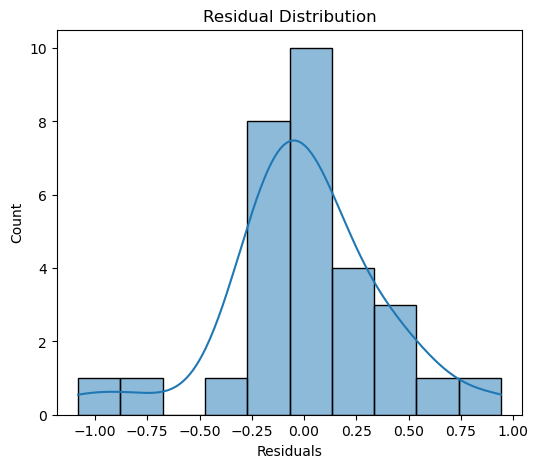

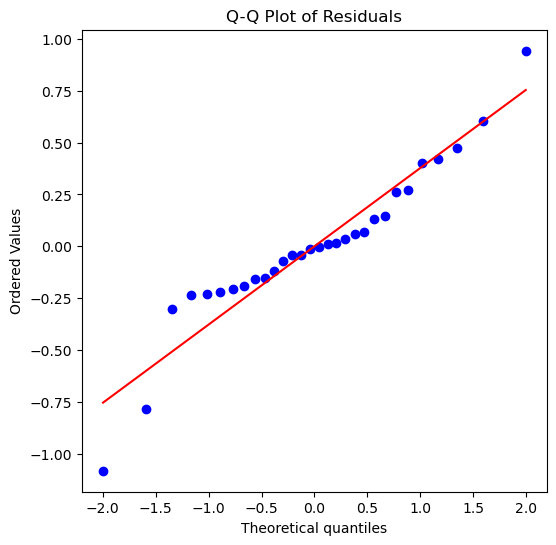


SHAPIRO-WILK TEST
W = 0.9322
p = 0.0564


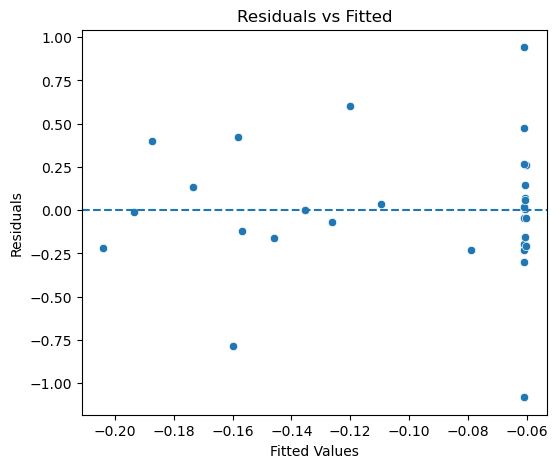

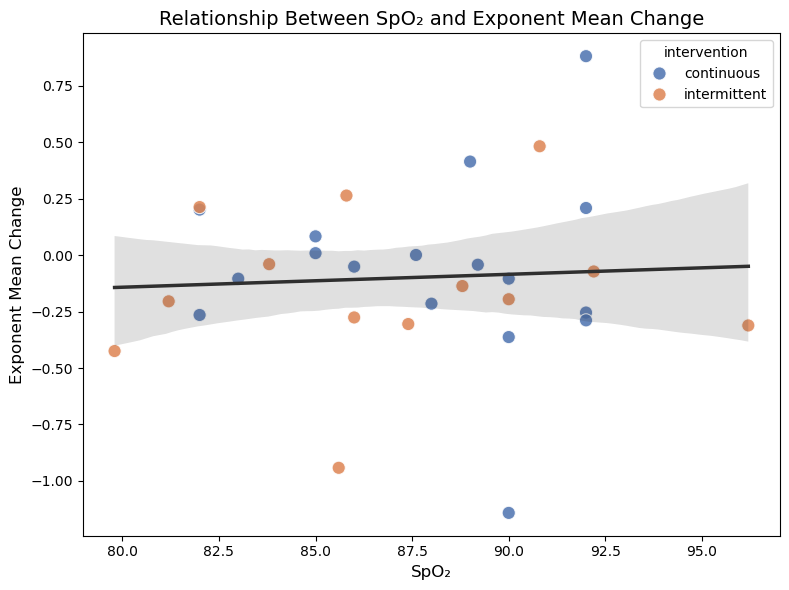

In [ ]:
# =====================================================
# CONFIGURATION
# =====================================================

FORMULA = (
    "exponent_mean_change ~ spo2 * intervention"
)

# =====================================================
# CREATE MODEL DATAFRAME
# =====================================================

model_df = df_eo[[

    'subject',
    'session',
    'intervention',
    'spo2',
    'exponent_mean_change'

]].copy()

# =====================================================
# REMOVE MISSING VALUES
# =====================================================

model_df = model_df.dropna().copy()

# =====================================================
# KEEP HYPOXIA ONLY
# =====================================================

model_df = model_df[
    model_df['session'] == 'ses-1'
].copy()

# =====================================================
# REMOVE OUTLIERS (3 SD)
# =====================================================

z_scores = stats.zscore(
    model_df['exponent_mean_change']
)

model_df['zscore'] = z_scores

rows_before = len(model_df)

model_df = model_df[
    np.abs(model_df['zscore']) < 3
].copy()

rows_after = len(model_df)

model_df = model_df.drop(
    columns='zscore'
)

print(
    "Rows removed:",
    rows_before - rows_after
)

# =====================================================
# RESET INDEX
# =====================================================

model_df = model_df.reset_index(
    drop=True
)

# =====================================================
# CATEGORICAL VARIABLES
# =====================================================

model_df['session'] = (
    model_df['session']
    .astype('category')
)

model_df['intervention'] = (
    model_df['intervention']
    .astype('category')
)

# =====================================================
# CHECK SAMPLE SIZE
# =====================================================

print("\n==============================")
print("FINAL SAMPLE")
print("==============================")

print(model_df.shape)

print(
    model_df['subject'].nunique(),
    "unique participants"
)

# =====================================================
# FIT ROBUST OLS MODEL
# =====================================================

model = smf.ols(

    FORMULA,

    data=model_df

).fit(
    cov_type='HC3'
)

print("\n==============================")
print("OLS MODEL")
print("==============================")

print(model.summary())

# =====================================================
# RESIDUALS
# =====================================================

residuals = model.resid

# =====================================================
# HISTOGRAM
# =====================================================

plt.figure(figsize=(6,5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Residual Distribution")

plt.xlabel("Residuals")

plt.show()

# =====================================================
# Q-Q PLOT
# =====================================================

plt.figure(figsize=(6,6))

stats.probplot(

    residuals,

    dist="norm",

    plot=plt
)

plt.title("Q-Q Plot of Residuals")

plt.show()

# =====================================================
# SHAPIRO-WILK TEST
# =====================================================

shapiro_test = stats.shapiro(
    residuals
)

print("\n==============================")
print("SHAPIRO-WILK TEST")
print("==============================")

print(
    f"W = {shapiro_test.statistic:.4f}"
)

print(
    f"p = {shapiro_test.pvalue:.4f}"
)

# =====================================================
# RESIDUALS VS FITTED
# =====================================================

fitted = model.fittedvalues

plt.figure(figsize=(6,5))

sns.scatterplot(
    x=fitted,
    y=residuals
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Fitted Values")

plt.ylabel("Residuals")

plt.title("Residuals vs Fitted")

plt.show()

# =====================================================
# SPO2 VS EXPONENT CHANGE
# =====================================================

sns.lmplot(

    data=model_df,

    x='spo2',

    y='exponent_mean_change',

    hue='intervention',

    height=6,

    aspect=1.3,

    scatter_kws={
        's': 80,
        'alpha': 0.8
    }
)

plt.xlabel("SpO₂")

plt.ylabel("Exponent Mean Change")

plt.title(
    "Relationship Between SpO₂ and Exponent Change"
)

plt.show()

In [124]:
model_df

,subject,session,intervention,spo2,alpha_pow_mean_change,zscore
0,2025-01-cont,ses-1,continuous,82.0,0.476071,1.391270
1,2025-02-cont,ses-1,continuous,89.0,0.009865,-0.068468
2,2025-03-cont,ses-1,continuous,92.0,0.024714,-0.021972
3,2025-04-cont,ses-1,continuous,92.0,0.317622,0.895148
4,2025-06-cont,ses-1,continuous,92.0,-0.210209,-0.757538
5,2025-07-cont,ses-1,continuous,92.0,0.111277,0.249064
6,2025-08-cont,ses-1,continuous,88.0,0.537087,1.582316
7,2025-10-cont,ses-1,continuous,86.0,-0.039848,-0.224122
8,2025-14-cont,ses-1,continuous,85.0,0.141389,0.343347
9,2025-15-cont,ses-1,continuous,85.0,0.334795,0.948919
